# Notebook 03 : implémentation du SVM linéaire avec scikit-learn

**Objectifs de ce notebook**

1. Présenter et préparer les deux jeux de données (cas séparable et cas non séparable).
2. Entraîner un SVM linéaire avec `scikit-learn` dans chacun des deux cas.
3. **Vérifier numériquement la théorie** (conditions KKT, forme du dual, vecteurs de support).
4. Visualiser la frontière de décision, la marge et les vecteurs de support.

Rappel des notations : $f(x)=w^\top x+b$, marge $=2/\|w\|$, multiplicateurs $\alpha_i$.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # pour importer le dossier src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

from src.data import generer_donnees_separables, generer_donnees_non_separables
from src.plots import tracer_donnees, tracer_svm

DOSSIER_FIGURES = os.path.abspath(os.path.join("..", "reports", "figures"))
os.makedirs(DOSSIER_FIGURES, exist_ok=True)

## 1. Présentation des jeux de données

**Cas séparable** : $n=80$ points, deux variables tirées uniformément sur $[0,1]$ puis centrées-réduites. La classe vaut $+1$ si $X_1>X_2$ et $-1$ sinon : la droite $X_1=X_2$ sépare donc exactement les deux classes.

**Cas non séparable** : $n=1000$ points, deux variables tirées uniformément sur $[0,1]$. L'étiquette est bruitée autour de la diagonale : $\mathbb{P}(Y=1)=0{,}95$ si $V_1\le V_2$ et $0{,}05$ sinon. Aucune droite ne peut donc séparer parfaitement les classes.

In [2]:
donnees_sep = generer_donnees_separables()
donnees_non_sep = generer_donnees_non_separables()

print("Cas séparable :", donnees_sep.shape)
print("Cas non séparable :", donnees_non_sep.shape)
print()
print("Répartition des classes (cas séparable) :")
print(donnees_sep["Y"].value_counts().sort_index())
print()
print("Répartition des classes (cas non séparable) :")
print(donnees_non_sep["Y"].value_counts().sort_index())
donnees_sep.head()

Cas séparable : (80, 3)
Cas non séparable : (1000, 3)

Répartition des classes (cas séparable) :
Y
-1    39
 1    41
Name: count, dtype: int64

Répartition des classes (cas non séparable) :
Y
0    510
1    490
Name: count, dtype: int64


,X1,X2,Y
0,0.800056,-0.666594,1
1,-0.879436,1.570685,-1
2,-1.122104,1.610981,-1
3,0.205935,-0.532063,1
4,0.894195,1.711678,-1


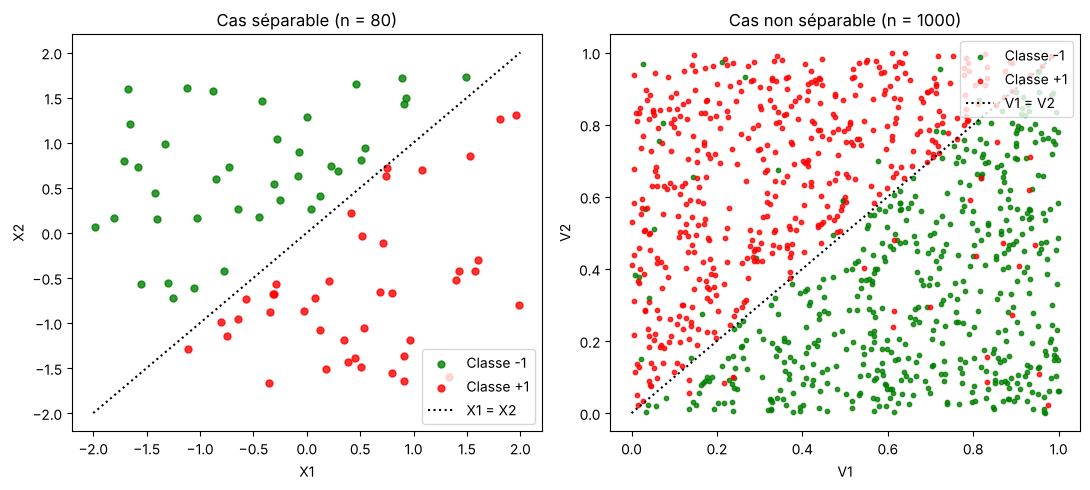

In [3]:
X_sep = donnees_sep[["X1", "X2"]].to_numpy()
y_sep = donnees_sep["Y"].to_numpy()                 # déjà dans {-1, +1}

X_ns = donnees_non_sep[["V1", "V2"]].to_numpy()
y_ns = 2 * donnees_non_sep["Y"].to_numpy() - 1      # {0, 1} -> {-1, +1}

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
tracer_donnees(X_sep, y_sep, ax=axes[0], titre="Cas séparable (n = 80)", xlabel="X1", ylabel="X2")
axes[0].plot([-2, 2], [-2, 2], "k:", label="X1 = X2")
axes[0].legend()
tracer_donnees(X_ns, y_ns, ax=axes[1], titre="Cas non séparable (n = 1000)", xlabel="V1", ylabel="V2", taille=10)
axes[1].plot([0, 1], [0, 1], "k:", label="V1 = V2")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_FIGURES, "fig6_jeux_de_donnees.png"), dpi=150)
plt.show()

## 2. Cas séparable : SVM à marge dure

### 2.1 Entraînement

Scikit-learn n'implémente que la marge souple. On obtient la **marge dure** en prenant $C$ très grand : les contraintes $y_i f(x_i)\ge 1$ deviennent alors pratiquement impossibles à violer. On utilise tout l'échantillon (80 points), car le but est de **vérifier la théorie** et non d'évaluer la généralisation.

In [4]:
modele_sep = SVC(kernel="linear", C=1e6, tol=1e-10)
modele_sep.fit(X_sep, y_sep)

w = modele_sep.coef_[0]            # vecteur w*
b = modele_sep.intercept_[0]       # biais b*
alpha_y = modele_sep.dual_coef_[0] # contient alpha_i * y_i pour les vecteurs de support
alpha = np.abs(alpha_y)
indices_sv = modele_sep.support_

print(f"w* = {w}")
print(f"b* = {b:.4f}")
print(f"Nombre de vecteurs de support : {len(indices_sv)}  (par classe : {modele_sep.n_support_})")
print(f"Marge = 2/||w*|| = {2/np.linalg.norm(w):.4f}")

w* = [ 7.57012815 -7.54818758]
b* = 0.7152
Nombre de vecteurs de support : 3  (par classe : [2 1])
Marge = 2/||w*|| = 0.1871


### 2.2 Vérification de la théorie

On contrôle que la solution trouvée par `scikit-learn` vérifie bien les résultats démontrés à la section 4 du rapport.

In [5]:
f = X_sep @ w + b
marge_fonctionnelle = y_sep * f      # y_i f(x_i)

tableau = pd.DataFrame({
    "Propriété vérifiée": [
        "(K1) w* = somme alpha_i y_i x_i : écart max",
        "(K2) somme alpha_i y_i = 0",
        "(K3) min_i y_i f(x_i) (doit être >= 1)",
        "(K5) y_i f(x_i) sur les vecteurs de support (doit valoir 1)",
        "Identité ||w*||^2 = somme alpha_i",
    ],
    "Valeur": [
        f"{np.max(np.abs(w - alpha_y @ modele_sep.support_vectors_)):.2e}",
        f"{alpha_y.sum():.2e}",
        f"{marge_fonctionnelle.min():.6f}",
        np.round(marge_fonctionnelle[indices_sv], 6).tolist(),
        f"{np.dot(w, w):.5f} contre {alpha.sum():.5f}",
    ],
})
tableau

,Propriété vérifiée,Valeur
0,(K1) w* = somme alpha_i y_i x_i : écart max,0.00e+00
1,(K2) somme alpha_i y_i = 0,-2.13e-14
2,(K3) min_i y_i f(x_i) (doit être >= 1),1.000000
3,(K5) y_i f(x_i) sur les vecteurs de support (d...,"[1.000004, 1.0, 1.000001]"
4,Identité ||w*||^2 = somme alpha_i,114.28198 contre 114.28183


In [6]:
# Les points qui ne sont pas des vecteurs de support sont strictement hors de la marge
hors_sv = np.setdiff1d(np.arange(len(y_sep)), indices_sv)
print("Plus petite valeur de y_i f(x_i) hors vecteurs de support :",
      round(marge_fonctionnelle[hors_sv].min(), 4), "(> 1)")
print("Précision sur l'échantillon :", accuracy_score(y_sep, modele_sep.predict(X_sep)))

print()
print("Multiplicateurs alpha_i non nuls :")
pd.DataFrame({"indice": indices_sv, "classe": y_sep[indices_sv], "alpha_i": alpha.round(4)})

Plus petite valeur de y_i f(x_i) hors vecteurs de support : 1.4376 (> 1)
Précision sur l'échantillon : 1.0

Multiplicateurs alpha_i non nuls :


,indice,classe,alpha_i
0,44,-1,22.8058
1,59,-1,34.3351
2,7,1,57.1409


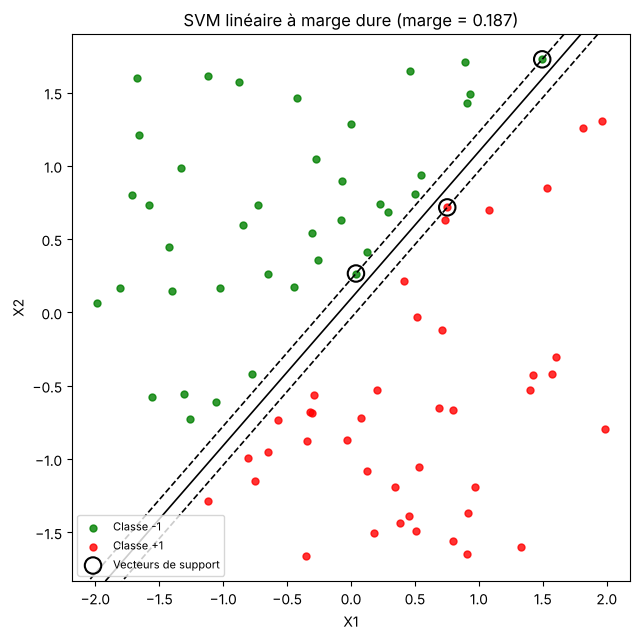

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
tracer_svm(modele_sep, X_sep, y_sep, ax=ax,
           titre=f"SVM linéaire à marge dure (marge = {2/np.linalg.norm(w):.3f})")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_FIGURES, "fig7_svm_separable.png"), dpi=150)
plt.show()

**Lecture.** Seuls quelques points (les vecteurs de support, cerclés) sont exactement sur le bord de la marge : ils vérifient $y_i f(x_i)=1$ et ont un multiplicateur $\alpha_i>0$. Tous les autres ont $y_i f(x_i)>1$ et $\alpha_i=0$ : ils n'interviennent pas dans $w^*=\sum_i\alpha_i^*y_ix_i$. C'est exactement la parcimonie annoncée par la condition de complémentarité.

### 2.3 Stabilité par rapport à $C$

Pour $C$ assez grand, la solution ne change plus : c'est la marge dure.

In [8]:
lignes = []
for C in [1, 10, 57.2, 100, 1e3, 1e6]:
    m = SVC(kernel="linear", C=C, tol=1e-10).fit(X_sep, y_sep)
    lignes.append({
        "C": C,
        "||w||": round(float(np.linalg.norm(m.coef_[0])), 4),
        "marge": round(float(2 / np.linalg.norm(m.coef_[0])), 4),
        "nb vecteurs de support": int(len(m.support_)),
        "alpha max": round(float(np.abs(m.dual_coef_[0]).max()), 3),
    })
pd.DataFrame(lignes)

,C,||w||,marge,nb vecteurs de support,alpha max
0,1.0,3.4083,0.5868,18,1.000
1,10.0,5.8474,0.3420,6,10.000
2,57.2,10.6903,0.1871,3,57.141
3,100.0,10.6903,0.1871,3,57.141
4,1000.0,10.6903,0.1871,3,57.141
5,1000000.0,10.6903,0.1871,3,57.141


Dès que $C$ dépasse le plus grand multiplicateur $\alpha_{\max}$ de la marge dure, la contrainte $\alpha_i\le C$ n'est plus active : on retrouve exactement la solution de la marge dure.

## 3. Cas non séparable : SVM à marge souple

### 3.1 Préparation des données

- étiquettes converties de $\{0,1\}$ en $\{-1,+1\}$ (déjà fait plus haut) ;
- séparation **entraînement / test** (70 % / 30 %), stratifiée selon la classe ;
- **standardisation** calculée sur l'échantillon d'entraînement uniquement, puis appliquée au test (pour éviter toute fuite d'information).

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_ns, y_ns, test_size=0.3, random_state=42, stratify=y_ns
)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Entraînement :", X_train_s.shape, "| Test :", X_test_s.shape)
print("Moyennes après standardisation (train) :", X_train_s.mean(axis=0).round(6))
print("Écarts-types après standardisation (train) :", X_train_s.std(axis=0).round(6))

Entraînement : (700, 2) | Test : (300, 2)
Moyennes après standardisation (train) : [-0.  0.]
Écarts-types après standardisation (train) : [1. 1.]


### 3.2 Entraînement avec $C=1$

L'étude détaillée de l'influence de $C$ sera faite dans le notebook 04. On fixe ici $C=1$.

In [10]:
C = 1.0
modele_ns = SVC(kernel="linear", C=C, tol=1e-6).fit(X_train_s, y_train)

w_ns = modele_ns.coef_[0]
b_ns = modele_ns.intercept_[0]
alpha_ns = np.abs(modele_ns.dual_coef_[0])

print(f"w* = {w_ns.round(4)},  b* = {b_ns:.4f}")
print(f"Marge = 2/||w*|| = {2/np.linalg.norm(w_ns):.4f}")
print(f"Nombre total de vecteurs de support : {len(alpha_ns)}")

w* = [-1.8362  1.7759],  b* = -0.0982
Marge = 2/||w*|| = 0.7829
Nombre total de vecteurs de support : 223


### 3.3 Les trois catégories de points

D'après les conditions KKT, chaque observation appartient à l'une des catégories suivantes :

| $\alpha_i$ | Position du point |
|---|---|
| $\alpha_i=0$ | bien classé, hors de la marge ou sur son bord |
| $0<\alpha_i<C$ | exactement sur le bord de la marge (vecteur de support « libre ») |
| $\alpha_i=C$ | dans la marge ou mal classé (vecteur de support « saturé ») |

In [11]:
n_train = len(y_train)
tol = 1e-6
n_zero = n_train - len(alpha_ns)
n_sature = int(np.sum(alpha_ns >= C - tol))
n_libre = len(alpha_ns) - n_sature

# Contrôle avec les valeurs de y_i f(x_i)
f_train = modele_ns.decision_function(X_train_s)
yf = y_train * f_train
mal_classes = int(np.sum(yf < 0))
dans_marge = int(np.sum((yf >= 0) & (yf < 1 - 1e-6)))

pd.DataFrame({
    "Catégorie": ["alpha = 0", "0 < alpha < C (libres)", "alpha = C (saturés)"],
    "Nombre de points": [n_zero, n_libre, n_sature],
})

,Catégorie,Nombre de points
0,alpha = 0,477
1,0 < alpha < C (libres),3
2,alpha = C (saturés),220


In [12]:
print(f"Points mal classés (y_i f(x_i) < 0)        : {mal_classes}")
print(f"Points bien classés mais dans la marge     : {dans_marge}")
print(f"Total des points avec y_i f(x_i) < 1       : {mal_classes + dans_marge}")
print(f"Points avec alpha_i = C                    : {n_sature}")

Points mal classés (y_i f(x_i) < 0)        : 43
Points bien classés mais dans la marge     : 177
Total des points avec y_i f(x_i) < 1       : 220
Points avec alpha_i = C                    : 220


Les points avec $y_if(x_i)<1$ sont **tous** saturés ($\alpha_i=C$) : c'est la condition de complémentarité $(C-\alpha_i)\xi_i=0$ vue à la section 4 du rapport. Les points saturés peuvent aussi inclure quelques points exactement sur le bord de la marge ($\xi_i=0$ et $\alpha_i=C$), cas limite.

### 3.4 Performances et visualisation

In [13]:
y_pred_train = modele_ns.predict(X_train_s)
y_pred_test = modele_ns.predict(X_test_s)

print(f"Précision (entraînement) : {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Précision (test)         : {accuracy_score(y_test, y_pred_test):.4f}")
print()
print("Matrice de confusion (test) — lignes : vrai, colonnes : prédit, ordre (-1, +1)")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_test, labels=[-1, 1]),
                   index=["vrai -1", "vrai +1"], columns=["prédit -1", "prédit +1"]))

# Précision de la frontière théorique V1 = V2 (la meilleure possible avec ce bruit)
y_theorique = np.where(donnees_non_sep["V1"] <= donnees_non_sep["V2"], 1, -1)
print()
print(f"Précision de la frontière théorique V1 = V2 sur tout l'échantillon : "
      f"{np.mean(y_theorique == y_ns):.4f}")

Précision (entraînement) : 0.9386
Précision (test)         : 0.9567

Matrice de confusion (test) — lignes : vrai, colonnes : prédit, ordre (-1, +1)
         prédit -1  prédit +1
vrai -1        146          7
vrai +1          6        141

Précision de la frontière théorique V1 = V2 sur tout l'échantillon : 0.9530


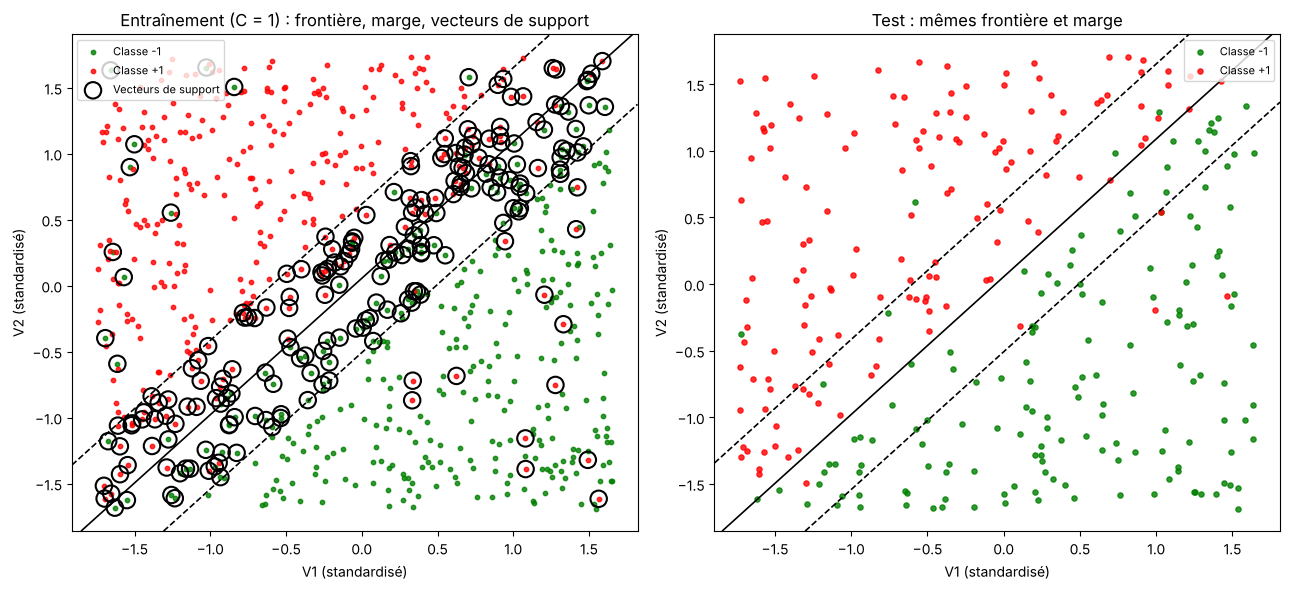

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
tracer_svm(modele_ns, X_train_s, y_train, ax=axes[0], taille=10,
           titre=f"Entraînement (C = {C:g}) : frontière, marge, vecteurs de support",
           xlabel="V1 (standardisé)", ylabel="V2 (standardisé)")
tracer_svm(modele_ns, X_test_s, y_test, ax=axes[1], taille=14, marge=True, montrer_sv=False,
           titre="Test : mêmes frontière et marge",
           xlabel="V1 (standardisé)", ylabel="V2 (standardisé)")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_FIGURES, "fig8_svm_non_separable.png"), dpi=150)
plt.show()

**Lecture.**

- La frontière est proche de la diagonale $V_1=V_2$ (en coordonnées standardisées), qui est la vraie frontière du modèle générateur.
- Environ 5 % des étiquettes sont bruitées : aucun classifieur linéaire ne peut dépasser environ 95 % de précision. La précision de test obtenue est cohérente avec cette limite.
- Environ un tiers des points d'entraînement (220 sur 700) sont des vecteurs de support saturés ($\alpha_i=C$) : avec $C=1$, la marge est large et contient beaucoup de points. Ce sont exactement les points tels que $y_if(x_i)<1$.

## 4. Bilan et suite

| | Cas séparable | Cas non séparable |
|---|---|---|
| Modèle | `SVC(kernel="linear", C=1e6)` | `SVC(kernel="linear", C=1)` |
| Vecteurs de support | très peu (points sur le bord de la marge) | beaucoup (points saturés, $\alpha_i=C$) |
| Théorie vérifiée | KKT, parcimonie, $\|w\|^2=\sum\alpha_i$ | trois catégories de points, bornes $0\le\alpha_i\le C$ |

**Prochaines étapes**

- Notebook 04 : influence de $C$ (largeur de la marge, nombre de vecteurs de support, performances) et choix de $C$ par validation croisée.
- Implémentation « maison » du dual avec `scipy.optimize` et comparaison avec `scikit-learn`.